(bulk-rna-seq)=
# Bulk RNA-seq

Test which genes change in a bulk RNA-seq experiment with {api}`limma_voom` on a cube of one group, which {api}`from_bulk` makes from a samples x genes matrix of counts: the analysis of pseudobulk profiles, applied to bulk samples. edgeR's quasi-likelihood F-tests and DESeq2, which model the counts themselves, are the alternatives, each checked against its R package ([Validation](../validation.md)). This page runs the three on one simulated experiment whose true changes are known, and compares their calls with the truth. [One matrix of counts](../statistics/count_models.md#one-matrix-of-counts) says how the methods differ, and the table at the end of the page gives the R function of each step.

The experiment is the simulated bulk dataset ([Datasets](../reference/datasets.md)): three treatments (control, drug A and drug B) with four replicates each, sequenced in two batches; drug A changes 500 of the 10,000 genes and drug B 300, and one sample, `drug_b_3`, is noisier than the others. `python docs/datasets.py prepare simulated_bulk` writes it, as a cube with one group, `bulk`.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool import Design, limma_voom, read_cube
from cytepool.normalization import filter_by_expression, tmm_factors
from cytepool.plotting import plot_dispersions, plot_quasi_dispersions
from cytepool.stats.deseq2 import (
    deseq2_likelihood_ratio_test,
    deseq2_wald_test,
    fit_deseq2,
)
from cytepool.stats.quasi_likelihood import (
    fit_quasi_likelihood,
    quasi_likelihood_f_test,
)

cube = read_cube("simulated_bulk.cube.zarr")
truth = np.load("simulated_bulk_truth.npz")
print(f"CytePool {cytepool.__version__}, numpy {np.__version__}")
print(cube)

CytePool 0.1.dev70+g194507939, numpy 2.5.4
Cube with 12 samples x 1 groups x 10,000 features
  layers: counts (uint32, lazy)
  cells per entry: not recorded
  samples: sample_id, condition, batch
  groups: group_id
  features: feature_id, symbol


## The design

The batch enters the model so that its shift of every gene does not count as noise. Both drugs are compared with the control, the reference level.


In [2]:
design = Design(
    cube.samples,
    "~ batch + condition",
    levels={"condition": ["control", "drug_a", "drug_b"]},
    contrasts={
        "drug_a_vs_control": "conditiondrug_a",
        "drug_b_vs_control": "conditiondrug_b",
    },
)
print(design)
print(design.check())

Design: 12 samples x 4 columns, formula '~ batch + condition'
  columns: (Intercept), batchbatch2, conditiondrug_a, conditiondrug_b
  contrasts: drug_a_vs_control, drug_b_vs_control
Design check: 12 samples, 4 columns, rank 4, 8 residual degrees of freedom; no
              problems found.


## limma-voom, with sample quality weights

{api}`limma_voom` runs on the cube's one group: genes are filtered by expression, TMM factors normalize the libraries, voom gives every observation a precision weight, and the contrasts are moderated by empirical Bayes ([What runs in each cell type](../statistics/limma_voom.md#limma-voom-steps)). `quality_weights=True` also estimates a weight for every sample from how closely it follows the model ([Sample quality weights](../statistics/limma_voom.md#sample-quality-weights)). The noisy sample gets a weight well below the others, so it counts less instead of being removed.


In [3]:
voom_result = limma_voom(cube, design, quality_weights=True)
print(voom_result)
samples = voom_result.samples
for sample_id, weight in zip(samples["sample_id"], samples["quality_weight"]):
    print(f"  {sample_id:<10} {weight:5.2f}  {'#' * round(20 * weight)}")

DifferentialExpressionResult (limma_voom): 1 group, 1 fitted; 2 contrasts:
    drug_a_vs_control, drug_b_vs_control
  bulk: 12 samples, 9,593 features
  control_1   1.12  ######################
  control_2   1.13  #######################
  control_3   1.10  ######################
  control_4   1.11  ######################
  drug_a_1    1.14  #######################
  drug_a_2    1.12  ######################
  drug_a_3    1.20  ########################
  drug_a_4    1.08  ######################
  drug_b_1    1.05  #####################
  drug_b_2    1.06  #####################
  drug_b_3    0.30  ######
  drug_b_4    1.18  ########################


## Choices

- **limma-voom, edgeR or DESeq2.** {api}`limma_voom` by default, whose tables carry the moderated standard errors that a [meta-analysis](../statistics/meta_analysis.md) combines across studies; edgeR's quasi-likelihood F-tests for the stricter error control that edgeR's User's Guide describes; DESeq2 with its Wald tests, or its likelihood ratio test of a reduced design, such as the batch alone here ([One matrix of counts](../statistics/count_models.md#one-matrix-of-counts)). The three are compared below.
- **Sample quality weights.** `quality_weights=True`, as above, when a sample may be of poor quality; [Normalization, filtering and sample quality](normalization_and_quality.ipynb) compares the calls with and without them.
- **The genes and the factors of edgeR and DESeq2.** {api}`fit_quasi_likelihood` takes the counts it is given, so filter them and pass TMM factors, as below; {api}`fit_deseq2` takes every gene, with DESeq2's size factors ([Defaults and choices](../statistics/count_models.md#count-models-defaults)).
- **The steps one by one.** The functions that {api}`limma_voom` calls also run alone on a matrix of counts, as the table at the end of the page lists them.

### edgeR's quasi-likelihood F-tests and DESeq2

{api}`fit_quasi_likelihood` and {api}`quasi_likelihood_f_test` take the counts of the genes that pass edgeR's filter ({api}`filter_by_expression`) with TMM factors ({api}`tmm_factors`). {api}`fit_deseq2` takes every gene and filters on the mean count when it adjusts the p-values; {api}`deseq2_wald_test` tests one contrast, and {api}`deseq2_likelihood_ratio_test` tests both drugs at once against the design with the batch only. {api}`plot_quasi_dispersions` draws edgeR's quasi-dispersions before and after moderation, as `plotQLDisp` does, and {api}`plot_dispersions` DESeq2's dispersion estimates, as `plotDispEsts` does.


9,593 of 10,000 genes pass the expression filter
quasi-likelihood: common dispersion 0.072, prior df 9.9
DESeq2 likelihood ratio test of both drugs: 563 genes at FDR 5%


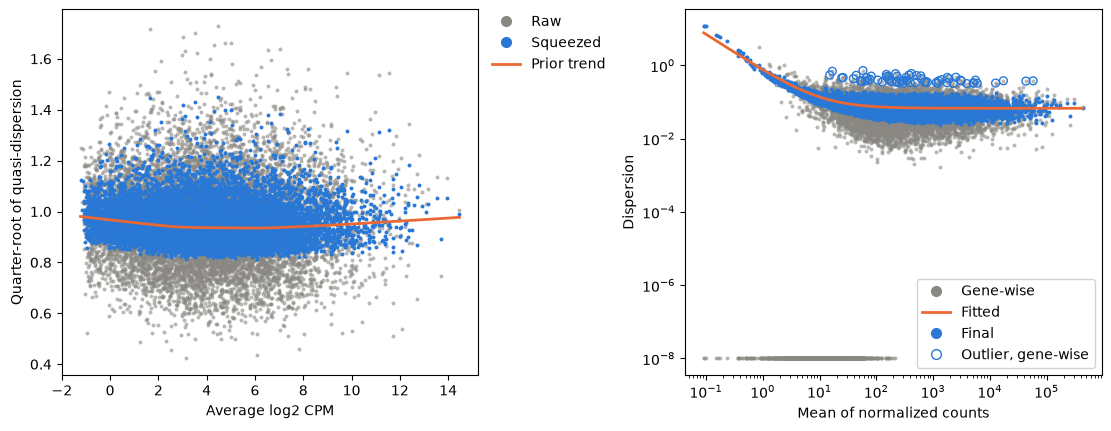

In [4]:
counts = cube.layer("counts", "bulk")
keep = filter_by_expression(counts, design=design)
quasi = fit_quasi_likelihood(
    counts[:, keep], design, norm_factors=tmm_factors(counts[:, keep])
)
deseq = fit_deseq2(counts, design)
either_drug = deseq2_likelihood_ratio_test(deseq, Design(cube.samples, "~ batch"))
print(f"{keep.sum():,} of {keep.size:,} genes pass the expression filter")
print(
    f"quasi-likelihood: common dispersion {quasi.dispersion:.3f}, prior df {np.median(quasi.df_prior):.1f}"
)
print(
    f"DESeq2 likelihood ratio test of both drugs: {np.sum(either_drug.adjusted_p_value < 0.05):,} genes at FDR 5%"
)
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
plot_quasi_dispersions(quasi, ax=left)
plot_dispersions(deseq, ax=right)
plt.show()

edgeR squeezes each gene's quasi-dispersion towards a prior trend that changes little with the expression level. DESeq2 shrinks each gene's dispersion towards a fitted trend that falls with the mean count to about 0.07, except for 64 dispersion outliers, whose own estimates lie far above the trend and are kept ([DESeq2](../statistics/count_models.md#deseq2)).

### Calls compared with the truth

At a false discovery rate of 5%, each method's calls are compared with the genes the simulation changed: how many it called, how many of those truly changed, and the share of its calls that are false. {api}`QuasiLikelihoodTest.table` and {api}`DESeq2Results.table` give edgeR's and DESeq2's tests as tables with the columns of the tables of {api}`limma_voom`, each gene named by its id (`feature_ids`), so that the three methods' calls are matched gene by gene.


In [5]:
genes = np.asarray(cube.features["feature_id"])
truly_changed = {
    "drug_a_vs_control": truth["true_log2_fold_change_drug_a"] != 0,
    "drug_b_vs_control": truth["true_log2_fold_change_drug_b"] != 0,
}


def called(table):
    # Whether each gene is called at a false discovery rate of 5%.
    return np.isin(genes, table["feature_id"][table["adjusted_p_value"] < 0.05])


print(f"{'contrast':<19}{'method':<18}{'called':>7}{'true':>7}{'false share':>13}")
for name in design.contrasts.names:
    contrast = design.contrasts.select(name)
    quasi_test = quasi_likelihood_f_test(quasi, contrasts=contrast)
    deseq_test = deseq2_wald_test(deseq, contrast)
    calls = {
        "limma-voom": called(voom_result.table(contrast=name)),
        "edgeR QL": called(quasi_test.table(feature_ids=genes[keep])),
        "DESeq2 Wald": called(deseq_test.table(feature_ids=genes)),
    }
    for method, call in calls.items():
        true_calls = np.sum(call & truly_changed[name])
        share = 1 - true_calls / max(call.sum(), 1)
        print(f"{name:<19}{method:<18}{call.sum():>7,}{true_calls:>7,}{share:>13.1%}")
    by_all = np.logical_and.reduce(list(calls.values()))
    print(f"{'':<19}{'called by all':<18}{by_all.sum():>7,}")

contrast           method             called   true  false share
drug_a_vs_control  limma-voom            355    337         5.1%
drug_a_vs_control  edgeR QL              320    312         2.5%
drug_a_vs_control  DESeq2 Wald           360    338         6.1%
                   called by all         320
drug_b_vs_control  limma-voom            204    192         5.9%
drug_b_vs_control  edgeR QL              193    184         4.7%
drug_b_vs_control  DESeq2 Wald           238    203        14.7%
                   called by all         188


The three methods find mostly the same genes: 320 genes are called by all three for drug A. They miss some of the changed genes, as the smallest simulated changes, a fold change of about 1.4, are hard to detect with four replicates. In this simulation DESeq2's Wald test made more false calls for drug B than the 5% that the adjustment allows on average, also when the noisy sample is left out; one simulated data set is no benchmark.


## The same steps in R

{api}`limma_voom` runs limma's steps in turn, and each step, like the edgeR and DESeq2 fits above, follows an R function. Run one by one, as a limma user would, the steps are these; R stores genes in rows, so its count matrix is the transpose of the one used here, and its library sizes are the totals of the genes kept, as here.

| Step | CytePool | R |
| --- | --- | --- |
| Filter genes | `keep = filter_by_expression(counts, design=design)`, then `counts[:, keep]` | `keep <- filterByExpr(y, design)`, then `y[keep, , keep.lib.sizes = FALSE]` |
| Normalization factors | `tmm_factors(counts)` | `calcNormFactors(y)` |
| Design and contrasts | `Design(samples, "~ batch + condition", contrasts=...)` | `model.matrix(~ batch + condition)` and `makeContrasts(...)` |
| Precision weights | `voom(counts, design, norm_factors=factors)` | `voom(y, design)` in limma 3.66 or later, `voom(y, design, adaptive.span = TRUE)` in 3.60 to 3.65 |
| The same, with sample quality weights | `voom_with_quality_weights(counts, design, norm_factors=factors)` | `voomWithQualityWeights(y, design)` |
| Linear models | `fit_linear_model(v.log2_cpm, design, weights=v.weights)` | `lmFit(v, design)` |
| Contrasts | `contrasts_fit(fit, design.contrasts, method="limma")` | `contrasts.fit(fit, contrasts)` |
| Moderation | `moderated = moderated_statistics(fit)` | `fit <- eBayes(fit)` |
| A contrast's table, with p-values adjusted by BH (`adjust_p_values`) | `moderated.table(j).sort("p_value")` | `topTable(fit, coef = j, number = Inf, sort.by = "P")` |
| Quasi-likelihood F-tests | `fit_quasi_likelihood`, then `quasi_likelihood_f_test`, then `.table()` | `glmQLFit`, then `glmQLFTest`, then `topTags` |
| DESeq2's Wald and likelihood ratio tests | `fit_deseq2`, then `deseq2_wald_test` or `deseq2_likelihood_ratio_test`, then `.table()` | `DESeq`, then `results`; `DESeq(dds, test = "LRT", reduced = ~ batch)` |

`method="limma"` gives the standard errors of contrasts as limma computes them; by default they are exact, which differs from limma's when the weights differ between genes and the contrast combines correlated coefficients ([Designs, linear models and contrasts](../statistics/linear_models.md#contrasts)). {api}`ModeratedFit.table` gives the table of one contrast with the columns of the tables of {api}`limma_voom`, as `topTable` does. The [Validation](../validation.md) page shows how closely each step agrees with R.
